In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import ramanspy as rpy
from sklearn.utils import shuffle

In [2]:
# Load CSV
df = pd.read_csv("Doentes/A9_com Glomerulopatia.csv", sep=";")
#df.columns = df.columns.str.strip() # to remove spaces from the names

# Inspect
#print(df.head(0))
print(df.columns.tolist())

['Wavenumber (cm-1)', 'Intensity (a.u.)']


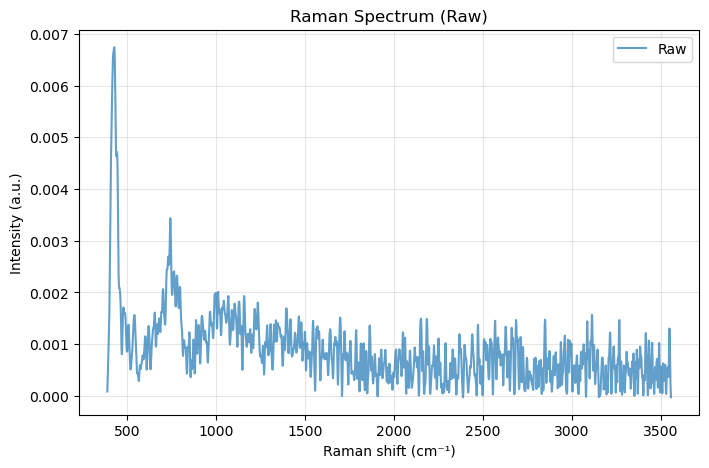

In [3]:
wavenumber = df.iloc[:, 0].values
intensity = df.iloc[:, 1].values

# === 2. Plot raw spectrum ===
plt.figure(figsize=(8, 5))
plt.plot(wavenumber, intensity, label="Raw", alpha=0.7)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Raman Spectrum (Raw)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [4]:
# === 3. Wrap as Raman Spectrum ===
spectrum = rpy.Spectrum(intensity, spectral_axis=wavenumber)

In [5]:
# === 4. Build preprocessing pipeline ===
#pipeline = rpy.preprocessing.Pipeline([
 #   rpy.preprocessing.denoise.SavGol(window_length=7, polyorder=3),  # Savitzky-Golay smoothing
 #   rpy.preprocessing.baseline.ASLS(lam=1e5, p=0.01),                # Asymmetric Least Squares
#    rpy.preprocessing.normalise.MinMax()                             # Min-Max normalization
#])


# === 4. Build preprocessing pipeline (adjusted parameters) ===
pipeline = rpy.preprocessing.Pipeline([
    rpy.preprocessing.denoise.SavGol(window_length=5, polyorder=2),   # Smaller window
    rpy.preprocessing.baseline.ASLS(lam=1e3, p=0.1),                 # Lower lambda
    rpy.preprocessing.normalise.MinMax()                              # Min-Max normalization
])
processed = pipeline.apply(spectrum)

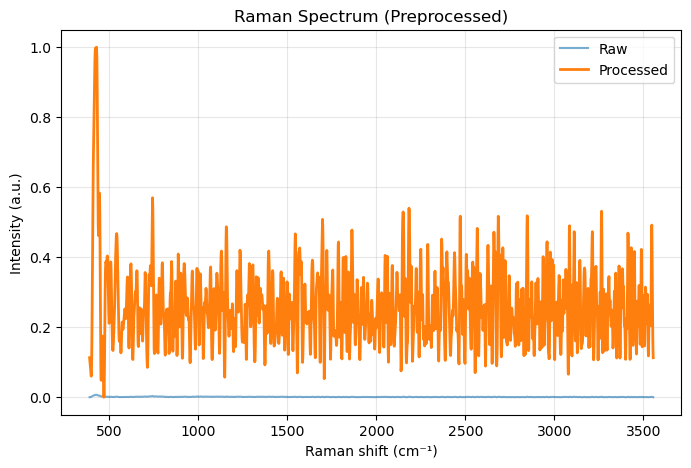

In [6]:
# === 5. Plot comparison ===
plt.figure(figsize=(8, 5))
plt.plot(spectrum.spectral_axis, spectrum.spectral_data, label="Raw", alpha=0.6)
plt.plot(processed.spectral_axis, processed.spectral_data, label="Processed", linewidth=2)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Raman Spectrum (Preprocessed)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [7]:
# Debug: Check data ranges
print(f"Wavenumber range: {wavenumber.min()} to {wavenumber.max()}")
print(f"Intensity range: {intensity.min()} to {intensity.max()}")
print(f"Spectrum spectral_axis range: {spectrum.spectral_axis.min()} to {spectrum.spectral_axis.max()}")
print(f"Spectrum spectral_data range: {spectrum.spectral_data.min()} to {spectrum.spectral_data.max()}")

Wavenumber range: 389.211 to 3555.79
Intensity range: -2.77552e-05 to 0.00674248
Spectrum spectral_axis range: 389.211 to 3555.79
Spectrum spectral_data range: -2.77552e-05 to 0.00674248


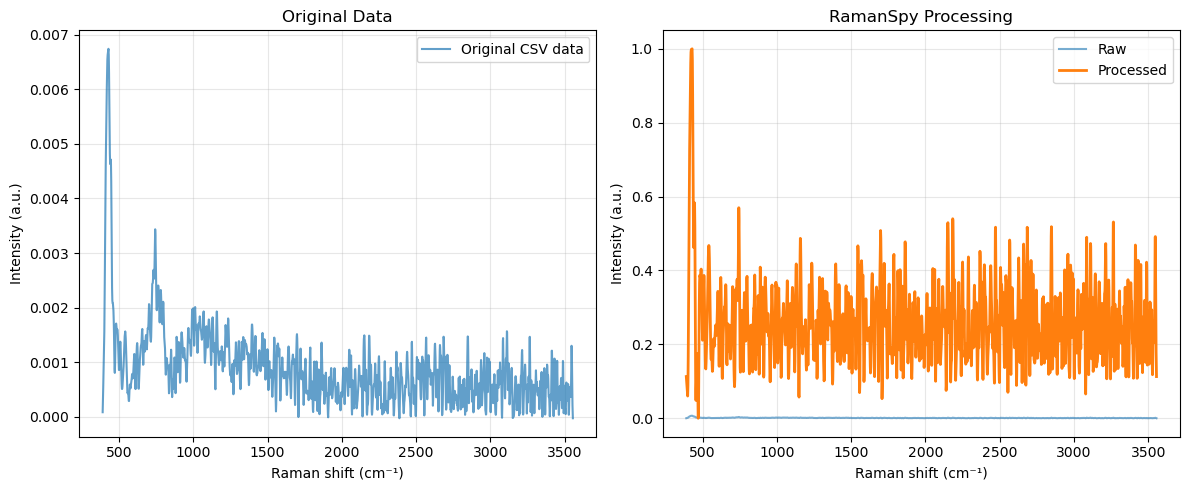

In [8]:
# === 5. Plot comparison ===
plt.figure(figsize=(12, 5))

# Left plot: Original data
plt.subplot(1, 2, 1)
plt.plot(wavenumber, intensity, label="Original CSV data", alpha=0.7)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Original Data")
plt.legend()
plt.grid(True, alpha=0.3)

# Right plot: RamanSpy processed
plt.subplot(1, 2, 2)
plt.plot(spectrum.spectral_axis, spectrum.spectral_data, label="Raw", alpha=0.6)
plt.plot(processed.spectral_axis, processed.spectral_data, label="Processed", linewidth=2)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("RamanSpy Processing")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


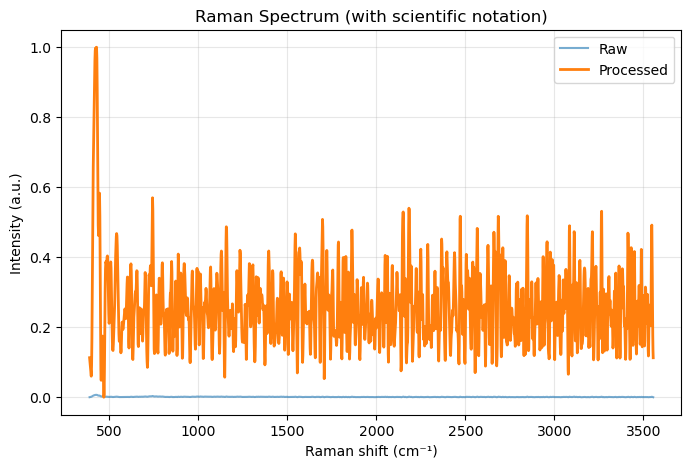

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(spectrum.spectral_axis, spectrum.spectral_data, label="Raw", alpha=0.6)
plt.plot(processed.spectral_axis, processed.spectral_data, label="Processed", linewidth=2)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Raman Spectrum (with scientific notation)")
plt.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

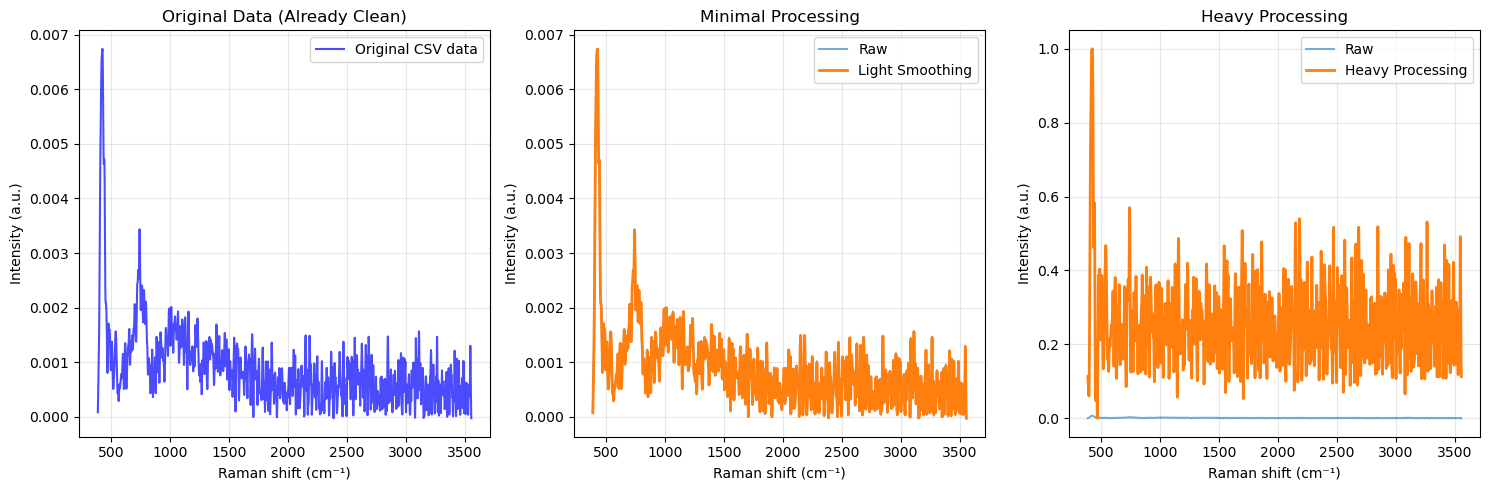

In [10]:
# Add this cell to compare minimal vs heavy processing
plt.figure(figsize=(15, 5))

# Original data
plt.subplot(1, 3, 1)
plt.plot(wavenumber, intensity, label="Original CSV data", alpha=0.7, color='blue')
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Original Data (Already Clean)")
plt.legend()
plt.grid(True, alpha=0.3)

# Minimal processing (just light smoothing)
pipeline_minimal = rpy.preprocessing.Pipeline([
    rpy.preprocessing.denoise.SavGol(window_length=5, polyorder=2),   # Very light smoothing only
])
processed_minimal = pipeline_minimal.apply(spectrum)

plt.subplot(1, 3, 2)
plt.plot(spectrum.spectral_axis, spectrum.spectral_data, label="Raw", alpha=0.6)
plt.plot(processed_minimal.spectral_axis, processed_minimal.spectral_data, label="Light Smoothing", linewidth=2)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Minimal Processing")
plt.legend()
plt.grid(True, alpha=0.3)

# Heavy processing (your current pipeline)
plt.subplot(1, 3, 3)
plt.plot(spectrum.spectral_axis, spectrum.spectral_data, label="Raw", alpha=0.6)
plt.plot(processed.spectral_axis, processed.spectral_data, label="Heavy Processing", linewidth=2)
plt.xlabel("Raman shift (cm⁻¹)")
plt.ylabel("Intensity (a.u.)")
plt.title("Heavy Processing")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()